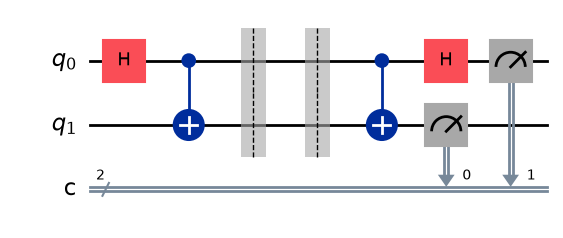

Measurement counts: {'00': 1024}
Decoded message: 00  | Correct: True


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error, depolarizing_error
def encode_gate(qc, qubit, bits):
 """Alice's encoding operation for a 2-bit message (b1, b0)."""
 b1, b0 = bits
 if b1 == 0 and b0 == 0:
     pass # I -> message 00
 elif b1 == 0 and b0 == 1:
     qc.x(qubit) # X -> message 01
 elif b1 == 1 and b0 == 0:
     qc.z(qubit) # Z -> message 10
 elif b1 == 1 and b0 == 1:
     qc.z(qubit); qc.x(qubit) # ZX -> message 11
def superdense_coding(bits):
 qc = QuantumCircuit(2, 2)
 qc.h(0); qc.cx(0, 1) # Step 1: share a Phi+ Bell pair
 qc.barrier()
 encode_gate(qc, 0, bits) # Step 2: Alice encodes on her qubit (q0)
 qc.barrier()
 qc.cx(0, 1); qc.h(0) # Step 3: Bob decodes after receiving q0
 # q0 reveals the Z-encoded (left) bit, q1 reveals the X-encoded (right) bit
 qc.measure(0, 1); qc.measure(1, 0)
 return qc
qc = superdense_coding((0, 0)) # message '00'
display(qc.draw(output='mpl', style='iqp'))
counts = AerSimulator().run(qc, shots=1024).result().get_counts()
print("Measurement counts:", counts)
print("Decoded message:", max(counts, key=counts.get), " | Correct:", '00' in counts and
counts['00'] == 1024)